In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad
from scipy.interpolate import CubicSpline
from numba import njit, prange

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

# Functions

In [3]:
def compute_mfpt_with_robin_boundary(r_target, rf, rn, D0, Dn, A, b, kappa):
    """ Calculate the double integral: 
    integral from r_target to r_n of (-exp(phi(r)))dr * integral from r to r_0 of (exp(phi(s))/D(s))ds, 
    + exp(phi(r_target)) / kappa * integral from r_target to r_n of (exp(-phi(r)))dr,
    where phi(r) = -2 * ln(r) + U(r) """

    def D_r(r):
        """Calculate the diffusion constant at distance r."""
        return D0 + (Dn - D0) / (1 + np.exp(-b * (r - rf)))
    
    def U_r(r):
        """Calculate the potential at distance r."""
        return A / (1 + np.exp(-b * (r - rf)))
    
    def phi(r):
        """ Define effective potential function for the MFPT calculation."""
        return -2 * np.log(r) + U_r(r)
    
    def inner_integrand(s):
        """Integrand for the inner integral."""
        return np.exp(phi(s)) / D_r(s)
    
    def inner_integral(r):
        """Inner integral from r to r_n."""
        return quad(inner_integrand, r_target, r)[0]
    
    def outer_integrand(r):
        """Integrand for outer integral: exp(-phi(r)) * inner_integral(r)"""
        return np.exp(-phi(r)) * inner_integral(r)
    
    def boundary_integral():
        """Calculate the boundary integral term."""
        return np.exp(phi(r_target)) / kappa * quad(lambda r: np.exp(-phi(r)), r_target, rn)[0]
    
    # Calculate the first term of the MFPT
    tau1, _ = quad(outer_integrand, r_target, rn)

    # Calculate the second term of the MFPT
    tau2 = boundary_integral()

    return tau1, tau2, tau1 + tau2

In [4]:
# Functions for simulating with the robin boundary condition 

@njit
def D_r(r, rf, D0, Dn, b):
    return D0 + (Dn - D0) * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def U_r(r, rf, A, b):
    return A * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def dU_r(r, rf, A, b):
    exp_term = np.exp(-b * (r - rf))
    return A * (b * exp_term) / ((1 + exp_term)**2)

@njit
def dD_r(r, rf, D0, Dn, b):
    exp_term = np.exp(-b * (r - rf))
    return (Dn - D0) * (b * exp_term) / ((1 + exp_term)**2)

@njit
def reflect_outer(r_try, rn):
    while r_try > rn:
        r_try = 2 * rn - r_try
    return r_try

@njit
def reflect_inner(r_try, r_target):
    r_try = 2 * r_target - r_try
    return r_try

@njit
def simulate(r0, r_target, rf, rn, A, b, D0, Dn, kappa, ndim=3, dt=1e-5, max_steps=1e9):
    r = r0
    t = 0.0

    for step in range(max_steps):
        
        D = D_r(r, rf, D0, Dn, b)
        dU = dU_r(r, rf, A, b)
        dD = dD_r(r, rf, D0, Dn, b)

        # Calculate the drift and diffusion terms
        drift = (ndim - 1) * D / r + dD - D * dU   # Effective drift term
        diffusion = np.sqrt(2 * D * dt) * np.random.normal()  # Diffusion term

        # Calculate the proposed new position
        r_try = r + drift * dt + diffusion

        r_try = reflect_outer(r_try, rn)

        if r_try < r_target:
            # Calculate the probability of absorption at the target
            absorption_prob = kappa * math.sqrt(math.pi * dt / D)
            if np.random.rand() < absorption_prob:
                return t + dt  # Absorbed at the target, return the time
            else:
                r_try = reflect_inner(r_try, r_target)  # Reflect back into the domain
                r_try = reflect_outer(r_try, rn)  # Ensure we don't go beyond the outer boundary
                
        r = r_try
        t += dt
    
    print("Warning: Max steps reached without hitting target.")
    return np.inf  # Return infinity if max steps reached without hitting target

@njit(parallel=True)
def run_simulation(r0, r_target, rf, rn, A, b, D0, Dn, kappa, ndim=3, N=500, dt=1e-5, max_steps=1e9):
    """Run N simulations for the initial position r0."""
    first_passage_times = np.empty(N, dtype=np.float32)

    for i in prange(N):
        first_passage_times[i] = simulate(r0, r_target, rf, rn, A, b, D0, Dn, kappa, ndim, dt, max_steps)

    return first_passage_times

In [5]:
# Build the double integral function for a range of b and r_f values 
A = 5.0 
b = 1000.0

r_target = 0.01
r_n = 0.5 

D0 = 0.05
Dn = 1.0

kappa = 5.0

rf_vals = np.linspace(0.025, 0.175, 25)

tau1 = np.zeros(len(rf_vals))
tau2 = np.zeros(len(rf_vals))
mfpt = np.zeros(len(rf_vals))

for i in range(len(rf_vals)):
    tau1[i], tau2[i], mfpt[i] = compute_mfpt_with_robin_boundary(r_target=r_target, 
                                                                 rf=rf_vals[i], 
                                                                 rn=r_n, 
                                                                 D0=D0, 
                                                                 Dn=Dn, 
                                                                 A=A, 
                                                                 b=b, 
                                                                 kappa=kappa)

In [6]:
# Identify the index of the minimum MFPT and corresponding r_f value
min_index = np.argmin(mfpt)
optimal_rf = rf_vals[min_index]
print(f"Optimal r_f for minimum MFPT: {optimal_rf:.4f} with MFPT: {mfpt[min_index]:.4f}")

# Identify the index of the minimum MFPT for the absorbing case
min_index_abs = np.argmin(tau1)
optimal_rf_abs = rf_vals[min_index_abs]
print(f"Optimal r_f for minimum MFPT (absorbing case): {optimal_rf_abs:.4f} with MFPT: {tau1[min_index_abs]:.4f}")

Optimal r_f for minimum MFPT: 0.0562 with MFPT: 1.7978
Optimal r_f for minimum MFPT (absorbing case): 0.0688 with MFPT: 1.0988


In [17]:
mfpt_simulated = np.zeros(len(rf_vals[::2]))
std_simulated = np.zeros(len(rf_vals[::2]))
for i in range(0, len(rf_vals), 2):
    first_passage_times = run_simulation(r0=r_n, 
                                         r_target=r_target, 
                                         rf=rf_vals[i], 
                                         rn=r_n, 
                                         A=A, 
                                         b=b, 
                                         D0=D0, 
                                         Dn=Dn, 
                                         kappa=kappa, 
                                         ndim=3, 
                                         N=250, 
                                         dt=1e-6)
    
    mfpt_simulated[i//2] = np.mean(first_passage_times)
    std_simulated[i//2] = np.std(first_passage_times)

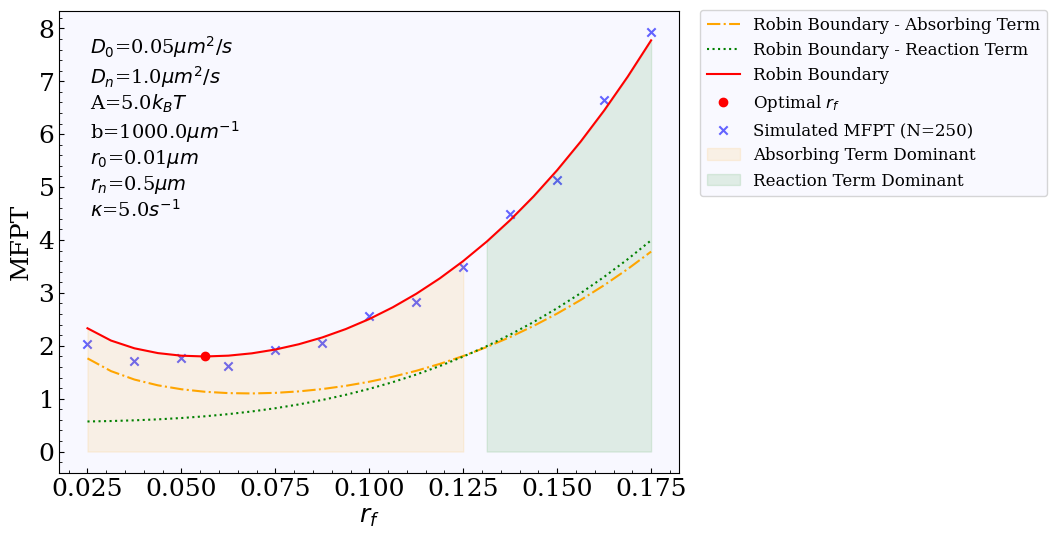

In [19]:
# Plot the MFPT as a function of r_f

fig, ax = plt.subplots(figsize=(8, 6))

# Plot the theoretical MFPT with Robin boundary condition, the absorbing term, and the reaction term separately
ax.plot(rf_vals, tau1, label='Robin Boundary - Absorbing Term', color='orange', linestyle='-.')
ax.plot(rf_vals, tau2, label='Robin Boundary - Reaction Term', color='green', linestyle=':')
ax.plot(rf_vals, mfpt, label=f'Robin Boundary', color='red')

# Plot the optimal r_f values for the Robin case and the absorbing case
ax.plot(optimal_rf, mfpt[min_index], 'ro', label=f'Optimal $r_f$')

# Plot simulated MFPT with error bars
#ax.errorbar(rf_vals, mfpt_simulated, yerr=std_simulated, fmt='o', color='blue', label='Simulated MFPT (N=500)', alpha=0.6)
ax.scatter(rf_vals[::2], mfpt_simulated, color='blue', marker='x', alpha=0.6, label='Simulated MFPT (N=250)')  # Connect the simulated points with a line

# Put the diffusion coefficient values and the potential A on the plot
ax.text(0.05, 0.95, f'$D_0$={D0}$\mu m^2/s$\n$D_n$={Dn}$\mu m^2/s$\nA={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa}$s^{{-1}}$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

# Fill the background where the absorbing term dominates (tau1 > tau2)
absorbing_dominant = tau1 > tau2
ax.fill_between(rf_vals, 0, mfpt, where=absorbing_dominant, color='orange', alpha=0.1, label='Absorbing Term Dominant')
ax.fill_between(rf_vals, 0, mfpt, where=~absorbing_dominant, color='green', alpha=0.1, label='Reaction Term Dominant')

ax.set_xlabel(r'$r_f$')
ax.set_ylabel('MFPT')
ax.legend(fontsize=12, bbox_to_anchor=(1.02, 1.02), loc='upper left')
plt.show()

# Scaling with diffusion coefficient

In [18]:
# Run for a range of D0-values for a fixed Dn

D0_vals = np.linspace(0.05, Dn, 20)
rf_vals = np.linspace(r_target, 0.05, 50)

tau1_D = np.zeros((len(D0_vals), len(rf_vals)))
tau2_D = np.zeros((len(D0_vals), len(rf_vals)))
mfpt_D = np.zeros((len(D0_vals), len(rf_vals)))

kappa = 1.0

for i in range(len(D0_vals)):
    for j in range(len(rf_vals)):
        tau1_D[i, j], tau2_D[i, j], mfpt_D[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0_vals[i], Dn, A, b, kappa=kappa)

In [27]:
# Check which term dominates for each D0 and rf value
absorbing_dominant_D = tau1_D > tau2_D

print(np.any(absorbing_dominant_D))

False


In [31]:
rf_vals_large = np.linspace(0.05, 0.1, 50)

tau1_D_k_large = np.zeros((len(D0_vals), len(rf_vals_large)))
tau2_D_k_large = np.zeros((len(D0_vals), len(rf_vals_large)))
mfpt_D_k_large = np.zeros((len(D0_vals), len(rf_vals_large)))

kappa_large = 50.0

for i in range(len(D0_vals)):
    for j in range(len(rf_vals_large)):
        tau1_D_k_large[i, j], tau2_D_k_large[i, j], mfpt_D_k_large[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals_large[j], r_n, D0_vals[i], Dn, A, b, kappa=kappa_large)

In [30]:
reaction_dominant_D_k_large = tau2_D_k_large > tau1_D_k_large

print(reaction_dominant_D_k_large)

[[False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False

In [20]:
def approx_opt_rf(D0, Dn, kappa, r_target, rn):
    D_ratio = D0 / Dn
    diffusion_reaction_ration = 1 / (1 + D0 / (kappa * r_target))
    absorbing_opt_rf = rn**3 * r_target / 3
    return (D_ratio * diffusion_reaction_ration * absorbing_opt_rf)**(1/4)

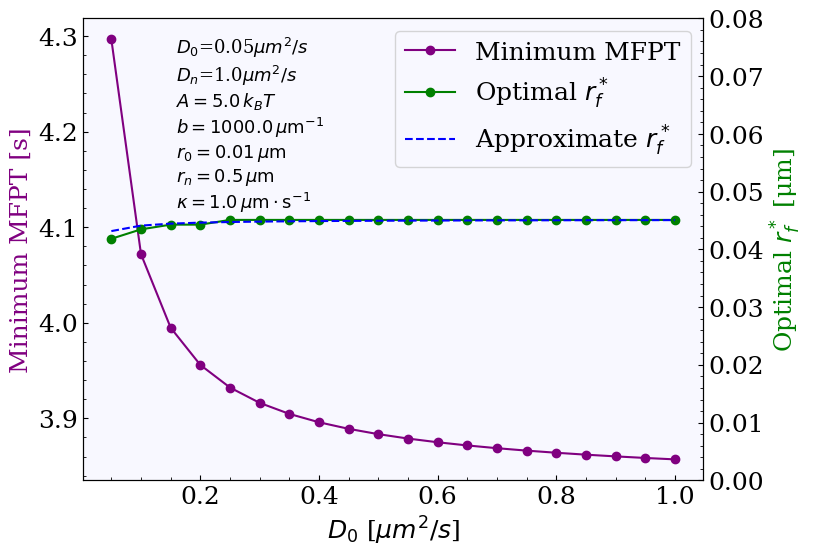

In [21]:
# Extract the optimal rf value and the corresponding MFPT for each D0 value
min_mfpt_D = np.min(mfpt_D, axis=1)
optimal_rf_D = rf_vals[np.argmin(mfpt_D, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D0_vals, min_mfpt_D, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel(r'$D_0$ [$\mu m^2/s$]')
ax.set_ylabel(r'Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D0_vals, optimal_rf_D, '-o', color='green', label='Optimal $r_f^*$')
ax2.plot(D0_vals, approx_opt_rf(D0_vals, Dn, kappa, r_target, r_n), '--', color='b', label='Approximate $r_f^*$')
ax2.set_ylim(0, 0.08)
ax2.set_ylabel(r'Optimal $r_f^*$ [μm]', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
text_str = rf"""
$D_0$={D0}$\mu m^2/s$
$D_n$={Dn}$\mu m^2/s$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.15, 1.01, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=13)

plt.show()

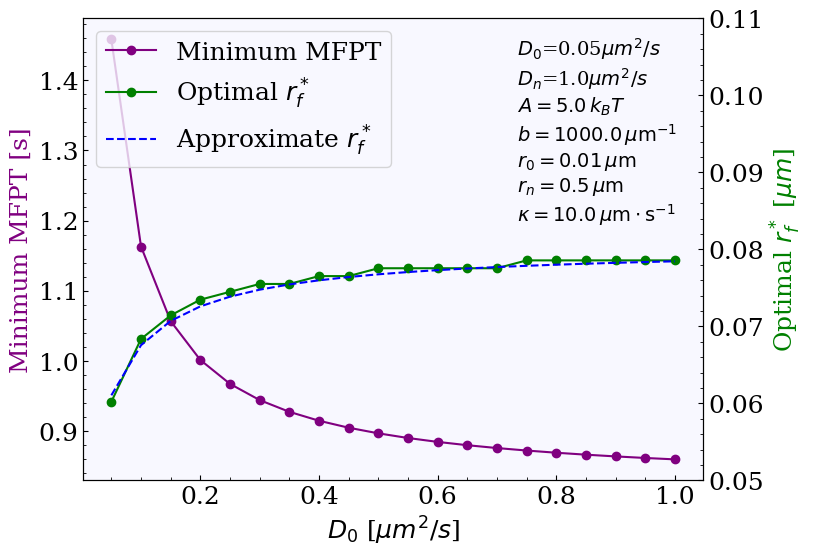

In [25]:
# Extract the optimal rf value and the corresponding MFPT for each D0 value
min_mfpt_D_k_large = np.min(mfpt_D_k_large, axis=1)
optimal_rf_D_k_large = rf_vals_large[np.argmin(mfpt_D_k_large, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D0_vals, min_mfpt_D_k_large, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel(r'$D_0$ [$\mu m^2/s$]')
ax.set_ylabel(r'Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D0_vals, optimal_rf_D_k_large, '-o', color='green', label='Optimal $r_f^*$')
ax2.plot(D0_vals, approx_opt_rf(D0_vals, Dn, kappa_large, r_target, r_n), '--', color='b', label='Approximate $r_f^*$')
ax2.set_ylim(0.05, 0.11)
ax2.set_ylabel(r'Optimal $r_f^*$ [$\mu m$]', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

# Put paramater values on the plot
text_str = rf"""
$D_0$={D0}$\mu m^2/s$
$D_n$={Dn}$\mu m^2/s$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa_large}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.7, 1.01, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [36]:
# Run for a range of D0-values for a fixed Dn
D0 = 0.05
Dn_vals = np.linspace(D0, 2.0, 20)
rf_vals = np.linspace(r_target, 0.1, 50)

tau1_Dn= np.zeros((len(Dn_vals), len(rf_vals)))
tau2_Dn = np.zeros((len(Dn_vals), len(rf_vals)))
mfpt_Dn = np.zeros((len(Dn_vals), len(rf_vals)))

kappa = 1.0

for i in range(len(Dn_vals)):
    for j in range(len(rf_vals)):
        tau1_Dn[i, j], tau2_Dn[i, j], mfpt_Dn[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0, Dn_vals[i], A, b, kappa=kappa)

In [37]:
# Run for a range of D0-values for a fixed Dn
D0 = 0.05
Dn_vals = np.linspace(D0, 2.0, 20)

rf_vals_large = np.linspace(0.04, 0.14, 50)
tau1_Dn_k_large= np.zeros((len(Dn_vals), len(rf_vals_large)))
tau2_Dn_k_large = np.zeros((len(Dn_vals), len(rf_vals_large)))
mfpt_Dn_k_large = np.zeros((len(Dn_vals), len(rf_vals_large)))

for i in range(len(Dn_vals)):
    for j in range(len(rf_vals_large)):
        tau1_Dn_k_large[i, j], tau2_Dn_k_large[i, j], mfpt_Dn_k_large[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals_large[j], r_n, D0, Dn_vals[i], A, b, kappa=kappa_large)

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3993913311.py:8: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('$D_n$ [$\mu m^2/s$]')


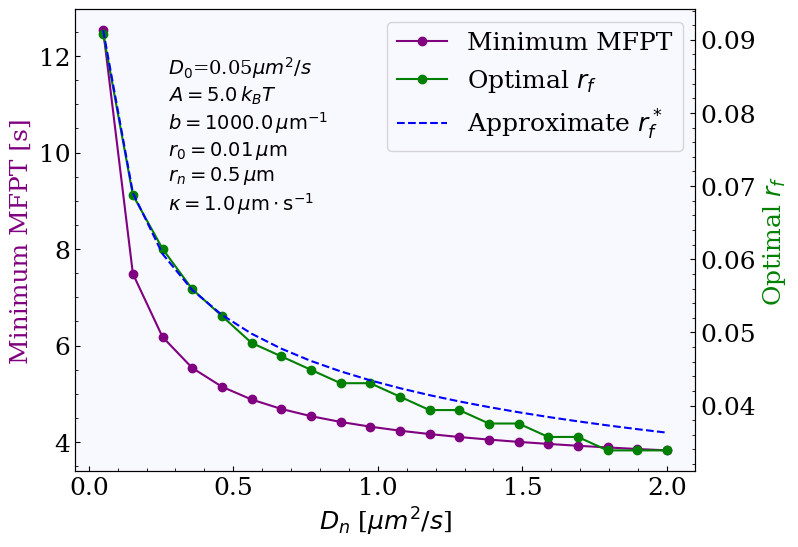

In [38]:
# Extract the optimal rf value and the corresponding MFPT for each Dn value
min_mfpt_Dn = np.min(mfpt_Dn, axis=1)
optimal_rf_Dn = rf_vals[np.argmin(mfpt_Dn, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Dn_vals, min_mfpt_Dn, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$D_n$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(Dn_vals, optimal_rf_Dn, '-o', color='green', label='Optimal $r_f$')
ax2.plot(Dn_vals, approx_opt_rf(D0, Dn_vals, kappa, r_target, r_n), '--', color='b', label='Approximate $r_f^*$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
text_str = rf"""
$D_0$={D0}$\mu m^2/s$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.15, 0.95, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3525545946.py:8: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('$D_n$ [$\mu m^2/s$]')


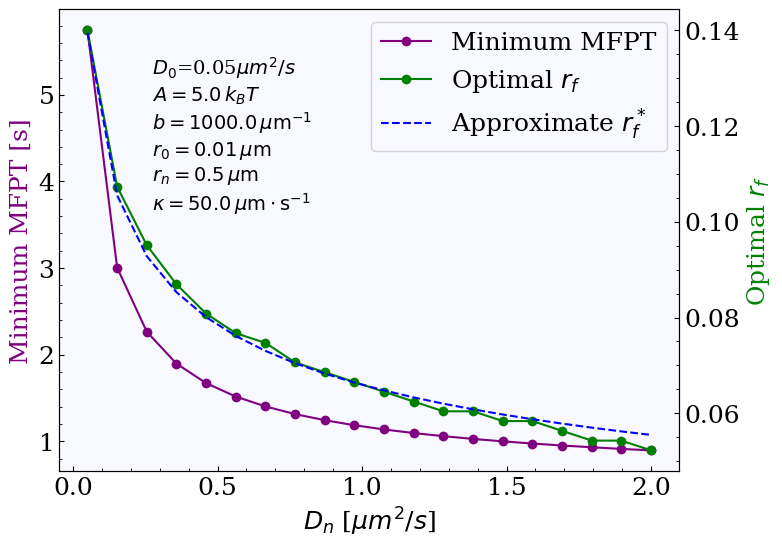

In [40]:
# Extract the optimal rf value and the corresponding MFPT for each Dn value
min_mfpt_Dn_k_large = np.min(mfpt_Dn_k_large, axis=1)
optimal_rf_Dn_k_large = rf_vals_large[np.argmin(mfpt_Dn_k_large, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Dn_vals, min_mfpt_Dn_k_large, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$D_n$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(Dn_vals, optimal_rf_Dn_k_large, '-o', color='green', label='Optimal $r_f$')
ax2.plot(Dn_vals, approx_opt_rf(D0, Dn_vals, kappa_large, r_target, r_n), '--', color='b', label='Approximate $r_f^*$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
text_str = rf"""
$D_0$={D0}$\mu m^2/s$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa_large}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.15, 0.95, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

# Scaling with potential strength A 

In [52]:
A_vals = np.linspace(1.0, 10.0, 20)
rf_vals = np.linspace(r_target, 0.05, 50)

tau1_A = np.zeros((len(A_vals), len(rf_vals)))
tau2_A = np.zeros((len(A_vals), len(rf_vals)))
mfpt_A = np.zeros((len(A_vals), len(rf_vals)))

kappa = 1.0

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        tau1_A[i, j], tau2_A[i, j], mfpt_A[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0, Dn, A_vals[i], b, kappa=kappa)

In [53]:
A_vals = np.linspace(1.0, 10.0, 20)
rf_vals_large = np.linspace(r_target, 0.8, 50)

tau1_A_k_large = np.zeros((len(A_vals), len(rf_vals_large)))
tau2_A_k_large = np.zeros((len(A_vals), len(rf_vals_large)))
mfpt_A_k_large = np.zeros((len(A_vals), len(rf_vals_large)))

for i in range(len(A_vals)):
    for j in range(len(rf_vals_large)):
        tau1_A_k_large[i, j], tau2_A_k_large[i, j], mfpt_A_k_large[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals_large[j], r_n, D0, Dn, A_vals[i], b, kappa=kappa_large)

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3659052387.py:13: RuntimeWarning: overflow encountered in exp
  return A / (1 + np.exp(-b * (r - rf)))
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3659052387.py:9: RuntimeWarning: overflow encountered in exp
  return D0 + (Dn - D0) / (1 + np.exp(-b * (r - rf)))


<>:7: SyntaxWarning: invalid escape sequence '\k'
<>:8: SyntaxWarning: invalid escape sequence '\k'
<>:7: SyntaxWarning: invalid escape sequence '\k'
<>:8: SyntaxWarning: invalid escape sequence '\k'
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3904590544.py:7: SyntaxWarning: invalid escape sequence '\k'
  axs[0, i].plot(rf_vals, mfpt_A[i*6], label=f'$\kappa =$ {kappa}', color='blue')
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/3904590544.py:8: SyntaxWarning: invalid escape sequence '\k'
  axs[1, i].plot(rf_vals_large, mfpt_A_k_large[i*6], label=f'$\kappa =$ {kappa_large}', color='red')


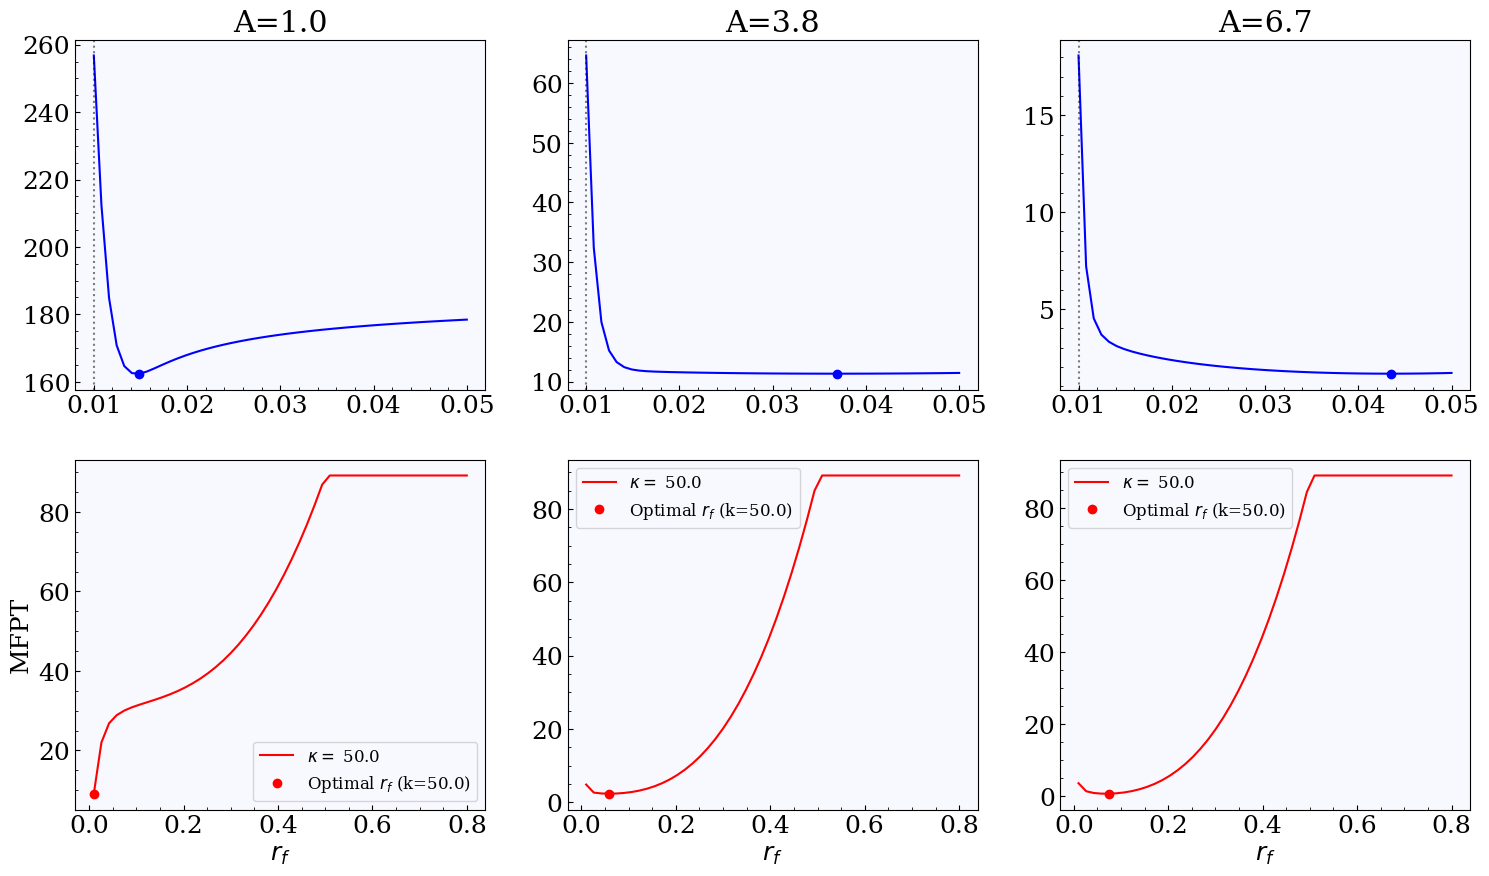

In [56]:
# Plot for 3 values of A, the mfpt as a function of rf

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for i in range(0, 3):
    opt_rf = rf_vals[np.argmin(mfpt_A, axis=1)]
    opf_rf_l = rf_vals_large[np.argmin(mfpt_A_k_large, axis=1)]
    axs[0, i].plot(rf_vals, mfpt_A[i*6], label=f'$\kappa =$ {kappa}', color='blue')
    axs[1, i].plot(rf_vals_large, mfpt_A_k_large[i*6], label=f'$\kappa =$ {kappa_large}', color='red')
    axs[0, i].plot(opt_rf[i*6], mfpt_A[i*6, np.argmin(mfpt_A[i*6])], 'bo', label=f'Optimal $r_f$ (k={kappa})')
    axs[1, i].plot(opf_rf_l[i*6], mfpt_A_k_large[i*6, np.argmin(mfpt_A_k_large[i*6])], 'ro', label=f'Optimal $r_f$ (k={kappa_large})')
    axs[0, i].axvline(r_target, color='k', linestyle=':', alpha=0.5)
    axs[0, i].set_title(f'A={A_vals[i*6]:.1f}')
    axs[1, i].set_xlabel(r'$r_f$')
    if i == 0:
        axs[1, i].set_ylabel('MFPT')
    axs[1, i].legend(fontsize=12)

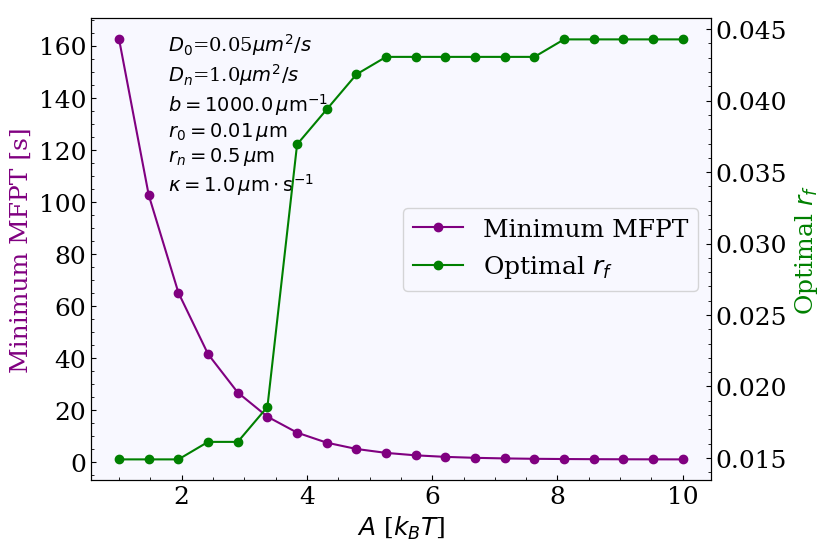

In [51]:
# Extract the optimal rf value and the corresponding MFPT for each D0 value
min_mfpt_A = np.min(mfpt_A, axis=1)
optimal_rf_A = rf_vals[np.argmin(mfpt_A, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$A$ [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='center right')

# Put paramater values on the plot
text_str = rf"""
$D_0$={D0}$\mu m^2/s$
$D_n$={Dn}$\mu m^2/s$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.125, 1.02, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/295065896.py:22: SyntaxWarning: invalid escape sequence '\m'
  ax.text(0.125, 0.95, f'$D_0$={D0}$\mu m^2/s$\n$D_n$={Dn}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa_large}$s^{{-1}}$',
/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_26794/295065896.py:22: SyntaxWarning: invalid escape sequence '\m'
  ax.text(0.125, 0.95, f'$D_0$={D0}$\mu m^2/s$\n$D_n$={Dn}$\mu m^2

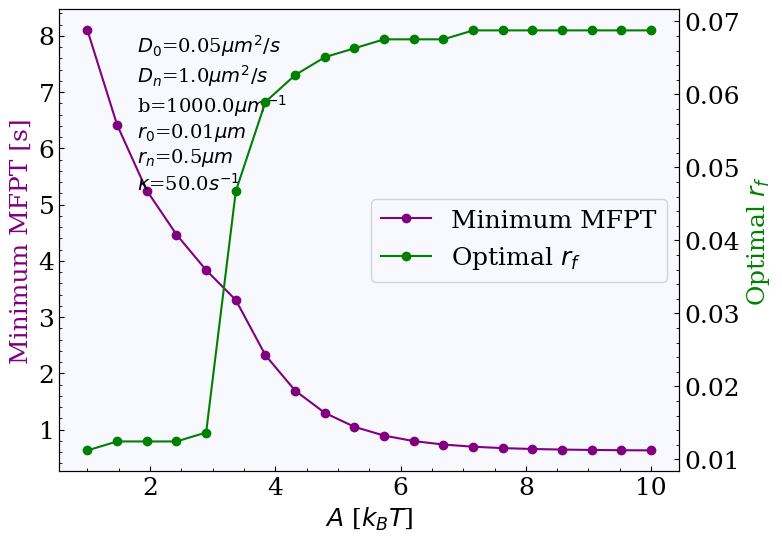

In [45]:
# Extract the optimal rf value and the corresponding MFPT for each D0 value
min_mfpt_A_k_large = np.min(mfpt_A_k_large, axis=1)
optimal_rf_A_k_large = rf_vals[np.argmin(mfpt_A_k_large, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A_k_large, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$A$ [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A_k_large, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='center right')

# Put paramater values on the plot
ax.text(0.125, 0.95, f'$D_0$={D0}$\mu m^2/s$\n$D_n$={Dn}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa_large}$s^{{-1}}$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [92]:
# For heterogenous diffusion, calculate the MFPT for a range of (D0, A)- values searching for the optimal rf value for each pair of (D0, A) values. 
Dn = 1.0
D0_vals = np.linspace(0.05, Dn, 5)
A_vals = np.linspace(1.0, 10.0, 5)
kappa = 1.0

tau1_D0_A = np.zeros((len(D0_vals), len(A_vals), len(rf_vals)))
tau2_D0_A = np.zeros((len(D0_vals), len(A_vals), len(rf_vals)))
mfpt_D0_A = np.zeros((len(D0_vals), len(A_vals), len(rf_vals)))

for i in range(len(D0_vals)):
    for j in range(len(A_vals)):
        for k in range(len(rf_vals)):
            tau1_D0_A[i, j, k], tau2_D0_A[i, j, k], mfpt_D0_A[i, j, k] = compute_mfpt_with_robin_boundary(r_target, rf_vals[k], r_n, D0_vals[i], Dn, A_vals[j], b, kappa=kappa)

In [93]:
# Find the optimal rf value for each pair of (D0, A) values and the corresponding minimum MFPT
optimal_rf_D0_A = np.zeros((len(D0_vals), len(A_vals)))
min_mfpt_D0_A = np.zeros((len(D0_vals), len(A_vals)))

for i in range(len(D0_vals)):
    for j in range(len(A_vals)):
        optimal_rf_D0_A[i, j] = rf_vals[np.argmin(mfpt_D0_A[i, j])]
        min_mfpt_D0_A[i, j] = np.min(mfpt_D0_A[i, j])

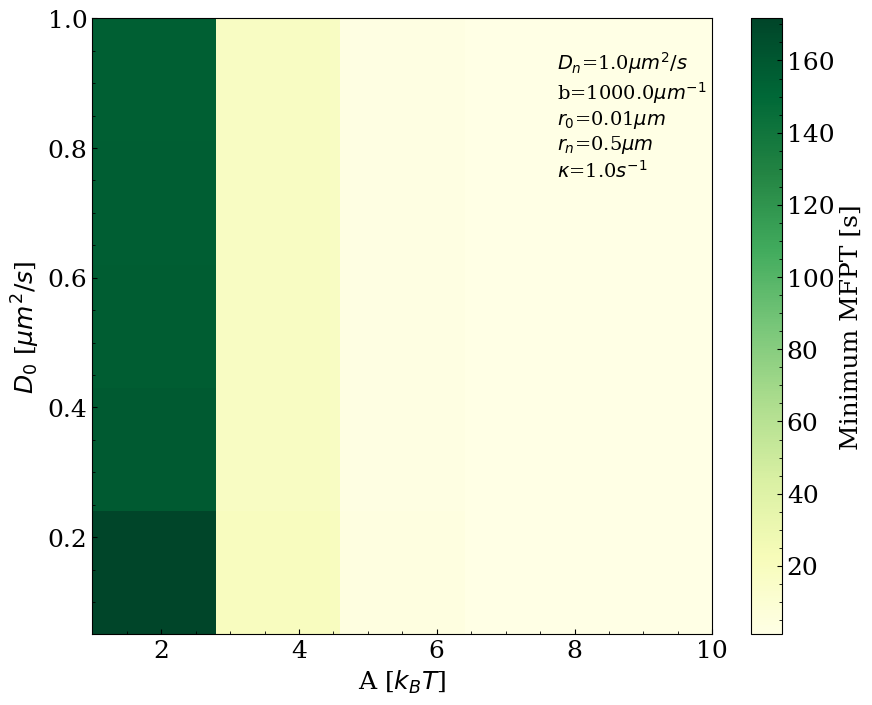

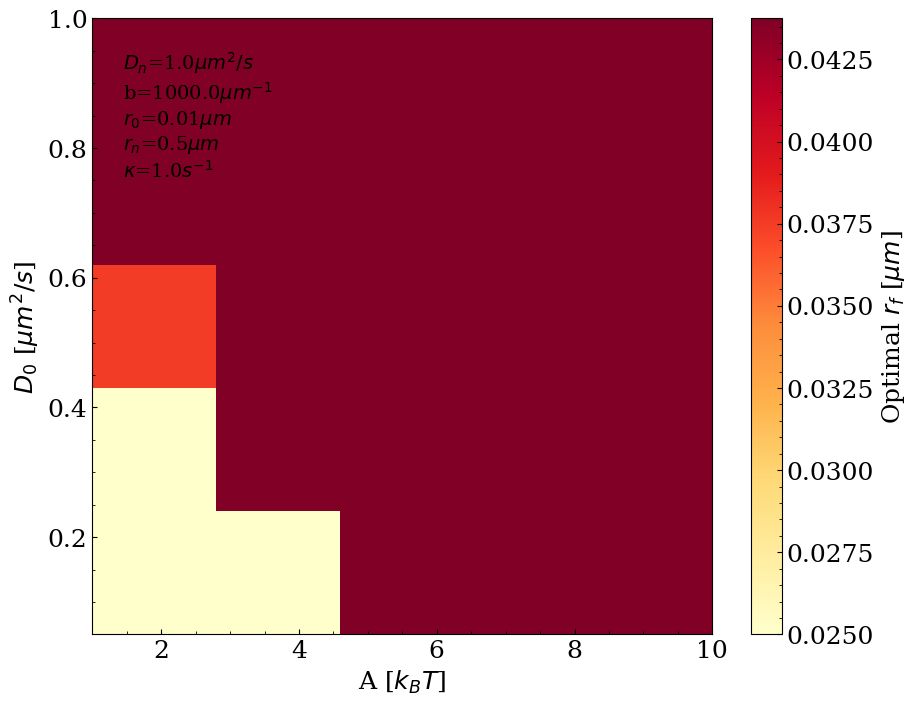

In [95]:
# Plot the minimum MFPT as a function of Dn and A using a heatmap, with the optimal rf value indicated by a marker on the plot.

fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(min_mfpt_D0_A, extent=[A_vals[0], A_vals[-1], D0_vals[0], D0_vals[-1]], 
              aspect='auto', origin='lower', cmap='YlGn')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('$D_0$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Minimum MFPT [s]')

# Put paramater values on the plot
ax.text(0.75, 0.95, f'$D_n$={Dn}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa}$s^{{-1}}$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(optimal_rf_D0_A, extent=[A_vals[0], A_vals[-1], D0_vals[0], D0_vals[-1]], 
              aspect='auto', origin='lower', cmap='YlOrRd')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('$D_0$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Optimal $r_f$ [$\mu m$]')
ax.text(0.05, 0.95, f'$D_n$={Dn}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa}$s^{{-1}}$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()
